# Power against underestimated PDs, and the exact rejection probabilities that need no simulation

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the rate and its Monte Carlo error, the size of every test)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- plant a miscalibration of known severity (every true PD is $k$ times the PD applied) and read the power of each calibration test against it, with its Monte Carlo error;
- compute the exact rejection probability of the count tests and of the traffic-lights test with the engine, check the simulated rates against it, and say where the two agree;
- find by root-finding the severity a test detects with 80% power, and reproduce the committed ratio of 1.2587 for the Jeffreys test;
- explain why the Vasicek-corrected binomial test gives up its power, and why the default-profile test cannot see a uniform underestimation.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import optimize

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `miscalibration` family of case C22 (validating the validator): every dataset is drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`), and in every one the PDs the test is given are $1/k$ of the true PDs, with $k$ on the ladder 1, 1.1, 1.25, 1.5, 2 and 3. The ladder is a design choice of Contraste, chosen so that the power curves run from the size to near one; it is not a statement about any bank. At $k = 1$ the null holds, so the first rung of each curve is a size.

- **File read:** `data/derived/C22/miscalibration.json`: `outputs.simulations` (54 rows: nine tests over the six rungs, 2,000 repetitions each), `outputs.generators` (configuration and truth of each), `outputs.panels`, `outputs.ladder` and `impact`.
- **Panels:** `portfolio` (count tests on 5,000 obligors at a PD of 2%), `grades` (seven grades), `obligors` (a logistic model of 5,000 obligors) and `years` (five years of 1,000 obligors at 3%).

The next cell loads the artifact and prints the ladder, the panels and what each panel measures.

In [2]:
# Load the miscalibration family, index its rows by key and print the ladder and the panels
LANG = "en"
ROOT = Path("../../..").resolve()
miscal = json.loads((ROOT / "data" / "derived" / "C22" / "miscalibration.json").read_text(encoding="utf-8"))
out = miscal["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]

print("baked by riskvalidation", miscal["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)
print("ladder:", out["ladder"]["label"][LANG], ladder)
measure_name = {"size": "size", "power": "power"}
for panel in out["panels"]:
    n_rows = sum(1 for row in rows.values() if row["panel"] == panel["id"])
    print(f"{panel['label'][LANG]:34s} {n_rows} rows | measures: {measure_name[panel['measures']]}")

baked by riskvalidation 0.4.3 | installed 0.9.0
ladder: true PD / PD applied [1.0, 1.1, 1.25, 1.5, 2.0, 3.0]
Portfolio count tests              18 rows | measures: power
Grade tests                        12 rows | measures: power
Obligor-level tests                12 rows | measures: power
Multi-year tests                   12 rows | measures: power


## Method

The power of a test against a defect is its rejection probability when the defect is present. The case estimates it as a rejection rate over 2,000 repetitions (Morris, White and Crowther, 2019, Table 6), at the 5% level, and for the tests that see the data only through a default count it also computes it exactly. With $D \sim \mathrm{Binomial}(n, \pi)$ defaults among $n$ obligors, a count test rejects exactly when $D \ge k^*_\alpha$, the smallest count whose p-value under the PD applied is below $\alpha$ (the engine finds it by calling the registered test). Under the true PD $\pi = k\cdot\mathrm{PD}$ the power is a binomial tail:

$$\text{power}(k) = P\big(D \ge k^*_\alpha\big), \qquad D \sim \mathrm{Binomial}\big(n,\; k\cdot \mathrm{PD}_{\text{applied}}\big)$$

The traffic-lights test needs the distribution of its colour profile over the years, which the engine builds by convolution, still without simulation. The steps plant the defect, read the simulated power, compute the exact power beside it, find the severity of 80% power, and then read the tests that behave differently.

### Step 1: the planted defect, on one dataset

The generator behind `pd.binomial@k1.5` is `default_counts`: 5,000 obligors, a true PD of 3% and a PD applied of 2%. Its truth says what is planted: 150 expected defaults where the PD applied expects 100, and `calibration_null_holds` false. The next cell rebuilds the generator from the committed configuration, draws one dataset and runs the binomial and Jeffreys tests on it, as a validator would on one year of data.

In [3]:
# Rebuild the generator of the k = 1.5 rung, read its truth, draw one dataset and run two tests on it
from riskvalidation.generators import DefaultCounts, feed_cell
from riskvalidation.validation import pd_binomial, pd_jeffreys

spec = out["generators"]["port-5000-k1.5"]
truth = spec["truth"]
print("true PD:", truth["pd_true"][0][0], "|", "PD applied:", truth["pd_forecast"][0][0], "|", "expected defaults:", truth["expected_defaults"][0][0],
      "|", "expected at the PD applied:", truth["obligors"][0][0] * truth["pd_forecast"][0][0])
print("the null holds:", truth["calibration_null_holds"])

generator = DefaultCounts(**spec["config"])
cell = feed_cell()(generator.draw(np.random.default_rng(5)))
print("one dataset: obligors", cell["n"], "|", "defaults", cell["d"])
for test in (pd_binomial, pd_jeffreys):
    result = test(**cell)
    print(f"{result.test_id:12s} p-value {result.p_value:.3e} | light {result.light.value}")

true PD: 0.03 | PD applied: 0.02 | expected defaults: 150.0 | expected at the PD applied: 100.0
the null holds: False
one dataset: obligors 5000 | defaults 159
pd.binomial  p-value 2.312e-08 | light red
pd.jeffreys  p-value 1.809e-08 | light red


### Step 2: the power of the count tests on the portfolio

The `portfolio` panel runs three count tests on 5,000 obligors at a PD of 2%: the binomial test, the Jeffreys test and the binomial test corrected for an asset correlation of 12% (`pd.binomial_vasicek`). Each row carries the simulated rate at 5%, its exact probability and an `agrees` flag. The next cell prints rate and exact value side by side along the ladder, and recomputes the agreement with the engine's `agrees` on the committed counts.

In [4]:
# Print the simulated rate and the exact power of the three count tests along the ladder and recompute the agreement
from riskvalidation.harness import Rate, agrees

count_tests = ("pd.binomial", "pd.jeffreys", "pd.binomial_vasicek")
print(f"{'k':>5s} " + " ".join(f"{t.split('.')[1][:14]:>16s}" for t in count_tests) + "   (simulated / exact, level 5%)")
agreeing, compared = 0, 0
for k in ladder:
    cells = []
    for test in count_tests:
        row = rows[f"{test}@k{k:g}"]
        c = row["rates"]["p<0.05"]
        cells.append(f"{c['rate']:.3f} / {row['exact']['p<0.05']:.3f}")
        for rule in ("p<0.05", "p<0.01"):
            cc = row["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(cc["rejections"], cc["n"]), row["exact"][rule])
    print(f"{k:5.2f} " + " ".join(f"{c:>16s}" for c in cells))
print("simulated rates that agree with their exact value (both levels):", agreeing, "of", compared)

    k         binomial         jeffreys   binomial_vasic   (simulated / exact, level 5%)
 1.00    0.038 / 0.041    0.047 / 0.050    0.000 / 0.000
 1.10    0.228 / 0.233    0.247 / 0.262    0.000 / 0.000
 1.25    0.760 / 0.749    0.797 / 0.778    0.000 / 0.000
 1.50    0.996 / 0.997    0.999 / 0.998    0.000 / 0.000
 2.00    1.000 / 1.000    1.000 / 1.000    0.000 / 0.000
 3.00    1.000 / 1.000    1.000 / 1.000    0.790 / 0.788
simulated rates that agree with their exact value (both levels): 36 of 36


### Step 3: the exact power, computed here

`rejection_probability` finds the critical count by calling the test and returns the binomial tail of the formula above. The next cell recomputes the exact power at 5% for the three count tests along the ladder, prints the critical count each test needs (against the 100 defaults the PD applied expects) and compares the result with the exact values the artifact stored. The Vasicek test needs a much higher count because it assumes the defaults of an obligor are correlated, which widens the distribution of the count it must tolerate.

In [5]:
# Recompute the exact power of the count tests along the ladder and compare it with the committed exact values
from riskvalidation.harness import rejection_probability

extra = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
largest_gap = 0.0
for test in count_tests:
    powers = []
    for k in ladder:
        exact = rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **extra[test])
        powers.append(exact["probability"])
        largest_gap = max(largest_gap, abs(exact["probability"] - rows[f"{test}@k{k:g}"]["exact"]["p<0.05"]))
    print(f"{test:20s} critical count {exact['critical_count']:4d} | exact power along the ladder", [round(p, 4) for p in powers])
print("largest gap to the committed exact values:", f"{largest_gap:.2e}")

pd.binomial          critical count  118 | exact power along the ladder [0.0413, 0.2325, 0.7491, 0.9973, 1.0, 1.0]
pd.jeffreys          critical count  117 | exact power along the ladder [0.0505, 0.2624, 0.7776, 0.998, 1.0, 1.0]
pd.binomial_vasicek  critical count  287 | exact power along the ladder [0.0, 0.0, 0.0, 0.0, 0.0, 0.7884]
largest gap to the committed exact values: 4.54e-10


### Step 4: the severity of 80% power

The committed headline `jeffreys_k80` is the ratio of true to applied PD at which the Jeffreys test has 80% power. Because the exact power is a smooth function of $k$ up to the discreteness of the critical count, a root finder locates it: the $k$ where $\text{power}(k) - 0.8$ changes sign. The next cell calls SciPy's `brentq` on the engine's exact power, with no simulation, and compares the root with the committed value. It then asks the same question of the binomial test, to say how much a PD must be too low before a validator running the binomial test would see it more often than not.

In [6]:
# Find the severity of 80% power with a root finder on the engine's exact power, for Jeffreys and for the binomial test
def power_gap(k, test):
    return rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k)["probability"] - 0.8

k80 = {test: optimize.brentq(power_gap, 1.0, 3.0, args=(test,), xtol=1e-12) for test in ("pd.jeffreys", "pd.binomial")}
print("Jeffreys, k at 80% power:", round(k80["pd.jeffreys"], 6), "|", "committed:", miscal["impact"]["jeffreys_k80"]["value"])
print("binomial, k at 80% power:", round(k80["pd.binomial"], 6))
print("the committed headline is the ratio of true to applied PD at 80% power (5000 obligors, PD 2%):", round(miscal["impact"]["jeffreys_k80"]["value"], 6))

Jeffreys, k at 80% power: 1.258663 | committed: 1.25866292
binomial, k at 80% power: 1.269036
the committed headline is the ratio of true to applied PD at 80% power (5000 obligors, PD 2%): 1.258663


### Step 5: what the Vasicek correction costs

The binomial test of the ECB treats the obligors as independent. The Vasicek-corrected version accepts that defaults share a systematic factor, with an assumed asset correlation of 12%, and widens its critical count to match (step 3). In these data the defaults are independent, so the correction protects against a risk that is not there, and what it costs is power. The next cell computes the exact power of the corrected test at larger severities, where the artifact's six rungs end, and finds the severity at which it reaches 80%.

In [7]:
# Exact power of the Vasicek-corrected test beyond the committed ladder, and its severity of 80% power
for k in (2.5, 3.0, 3.5, 4.0):
    power = rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=0.02 * k, rho=0.12)["probability"]
    print(f"k = {k:3.1f} | exact power of the corrected test {power:.4f}")

def vasicek_gap(k):
    return rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=0.02 * k, rho=0.12)["probability"] - 0.8

k80_vasicek = optimize.brentq(vasicek_gap, 2.0, 4.0, xtol=1e-12)
print("corrected test, k at 80% power:", round(k80_vasicek, 4), "|", "binomial:", round(k80["pd.binomial"], 4))

k = 2.5 | exact power of the corrected test 0.0100
k = 3.0 | exact power of the corrected test 0.7884
k = 3.5 | exact power of the corrected test 0.9999
k = 4.0 | exact power of the corrected test 1.0000
corrected test, k at 80% power: 3.0069 | binomial: 1.269


### Step 6: the other tests, simulated

The other three panels have no closed form except for the traffic lights. The `grades` panel runs the chi-square over seven grades and the default-profile test, the `obligors` panel runs Hosmer-Lemeshow and Spiegelhalter on a logistic model whose odds are divided by $k$, and the `years` panel runs the multi-year normal test and the traffic lights over five years at a PD of 3%. The next cell prints their simulated power along the ladder with the exact value of the traffic-lights test beside the committed one. Rejection at $k = 1$ is the size.

In [8]:
# Print the simulated power of the grade, obligor and year tests along the ladder, with the exact traffic-lights power beside the committed one
from riskvalidation.harness import traffic_lights_rejection_probability

others = ("pd.chi2_grades", "pd.default_profile", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
print(f"{'k':>5s} " + " ".join(f"{t.split('.')[1][:11]:>12s}" for t in others) + f" {'TL exact':>9s}")
for k in ladder:
    rates = [rows[f"{t}@k{k:g}"]["rates"]["p<0.05"]["rate"] for t in others]
    exact_tl = traffic_lights_rejection_probability([1000] * 5, 0.03, 0.05, pd_true=0.03 * k)["probability"]
    stored_tl = rows[f"pd.traffic_lights@k{k:g}"]["exact"]["p<0.05"]
    print(f"{k:5.2f} " + " ".join(f"{r:12.3f}" for r in rates) + f" {exact_tl:9.4f}", "(committed", f"{stored_tl:.4f})")

    k  chi2_grades  default_pro  hosmer_leme  spiegelhalt  normal_mult  traffic_lig  TL exact
 1.00        0.053        0.033        0.050        0.053        0.077        0.043    0.0379 (committed 0.0379)
 1.10        0.160        0.038        0.168        0.412        0.370        0.278    0.2521 (committed 0.2521)
 1.25        0.661        0.037        0.649        0.946        0.863        0.806    0.8019 (committed 0.8019)
 1.50        0.995        0.036        0.995        1.000        1.000        1.000    0.9985 (committed 0.9985)
 2.00        1.000        0.033        1.000        1.000        1.000        1.000    1.0000 (committed 1.0000)
 3.00        1.000        0.024        1.000        1.000        1.000        1.000    1.0000 (committed 1.0000)


### Step 7: the default-profile test is blind to the level

The default-profile test compares the shape of the observed defaults over the grades with the shape the PDs imply, and not their level (the `F-PROFILE-BLIND` finding of the artifact). If every PD is too low by the same factor, the shape is unchanged. The next cell prints the test's rate along the ladder next to the chi-square over grades, which does see the level, and the finding's text from the artifact.

In [9]:
# Compare the default-profile test with the chi-square over grades and print the artifact's finding
for test in ("pd.default_profile", "pd.chi2_grades"):
    rates = [rows[f"{test}@k{k:g}"]["rates"]["p<0.05"]["rate"] for k in ladder]
    print(f"{test:20s}", [round(r, 3) for r in rates])
finding = next(f for f in miscal["findings"] if f["id"] == "F-PROFILE-BLIND")
status_name = {"accepted": "accepted", "closed": "closed", "open": "open"}
print(finding["id"], finding["severity"], status_name[finding["status"]], "|", finding["title"][LANG])

pd.default_profile   [0.033, 0.038, 0.037, 0.036, 0.033, 0.024]
pd.chi2_grades       [0.053, 0.16, 0.661, 0.995, 1.0, 1.0]
F-PROFILE-BLIND S4 accepted | The default-profile test sees the shape of the PD curve, not its level: a uniform underestimation leaves it at its size


### Step 8: the power curves, drawn

The last cell draws the four panels. Each point is a simulated rate with its Wilson interval, the crosses are the exact power of the count tests and the traffic lights computed above and stored in the artifact, and the dashed line is the nominal 5%. A curve that starts at 5% at $k = 1$ and climbs to 1 is a test that holds its size and has power; a curve that starts near 0 is conservative, and one that stays flat is blind.

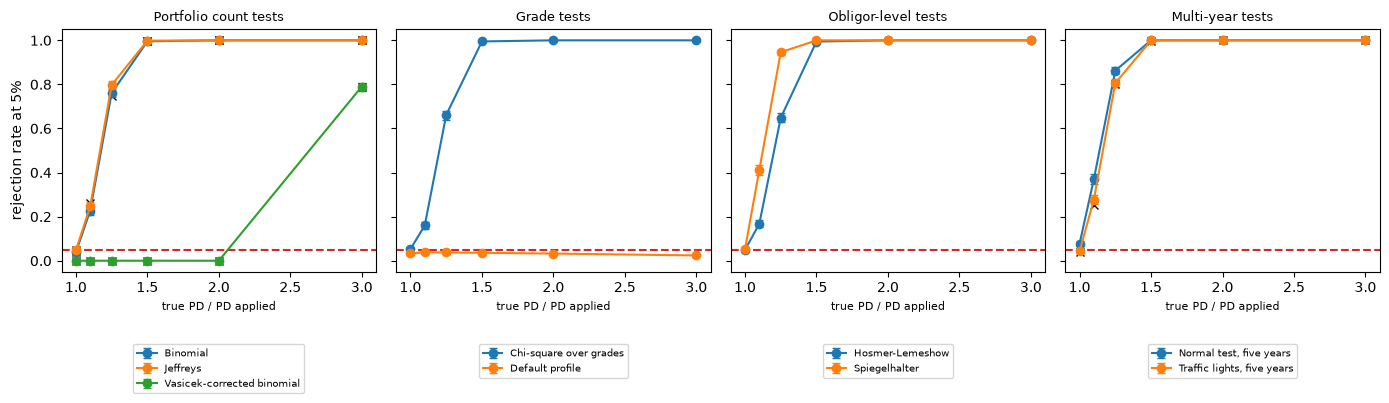

In [10]:
# Draw the simulated power with Wilson intervals and the exact power for the four panels
panel_tests = {"portfolio": count_tests, "grades": ("pd.chi2_grades", "pd.default_profile"),
               "obligors": ("pd.hosmer_lemeshow", "pd.spiegelhalter"), "years": ("pd.normal_multiperiod", "pd.traffic_lights")}
fig, axes = plt.subplots(1, 4, figsize=(14, 4.4), sharey=True)
for ax, panel in zip(axes, out["panels"]):
    for index, test in enumerate(panel_tests[panel["id"]]):
        points = [rows[f"{test}@k{k:g}"] for k in ladder]
        rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
        low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
        high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
        color = f"C{index}"
        ax.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=color, label=points[0]["label"][LANG])
        if points[0]["exact"] is not None:
            ax.plot(ladder, [p["exact"]["p<0.05"] for p in points], "x", color="black")
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_title(panel["label"][LANG], fontsize=9)
    ax.set_xlabel(out["ladder"]["label"][LANG], fontsize=8)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.28))
axes[0].set_ylabel("rejection rate at 5%")
fig.tight_layout()
plt.show()

## Results

- **The defect is visible on one dataset when it is large enough.** With a true PD of 3% against 2% applied, one dataset of 5,000 obligors had 159 defaults where the PD applied expects 100, and both the binomial and the Jeffreys tests were red (p about 2e-8). The ladder asks how small a defect can be before that stops being the usual outcome.
- **Count tests: power rises fast between 10% and 50% too low.** The binomial test rejects 22.8% of the time when every PD is 10% too low, 76.0% at 25% too low and 99.6% at 50% too low; the Jeffreys test 24.7%, 79.7% and 99.9%. The exact values are 23.3%, 74.9% and 99.7% for the binomial test and 26.2%, 77.8% and 99.8% for the Jeffreys test, and all 36 simulated rates agree with their exact value.
- **The exact computation reproduces the artifact.** Recomputed live, the exact power differs from the stored one by at most 4.5e-10. The binomial test rejects from 118 defaults and the Jeffreys test from 117, against 100 expected, and the 80% power severity of the Jeffreys test is 1.258663 against the committed 1.25866292. The binomial test needs a ratio of 1.2690. Read as a statement about this portfolio: a PD must be about 26% too low before a Jeffreys test on 5,000 obligors at a PD of 2% sees it four times in five.
- **Correcting for a correlation that is not there costs the power.** The Vasicek-corrected binomial test needs 287 defaults to reject, and in these independent data it rejects essentially nothing up to a ratio of 2 (1.0% at 2.5) and reaches 78.8% at a ratio of 3 (80% at 3.0069). The correction is a protection against clustering (notebook 04), and in data without clustering it is paid for in power.
- **The size is part of the curve.** At $k = 1$ the exact size at 5% of the binomial test is 4.13% and of the Jeffreys test 5.05%. The multi-year normal test starts at 7.7% (notebook 02), so part of its 37.0% at $k = 1.1$ is false alarm, not detection. A power number is read against the size at the first rung.
- **Obligor-level tests are not all equal.** At 25% too low, Spiegelhalter rejects 94.6% against 64.9% for Hosmer-Lemeshow and 66.1% for the chi-square over grades, because it uses every obligor instead of ten groups or seven grades. The traffic-lights test, which needs no simulation, reaches 80.6% (exact 80.19%) with five years of 1,000 obligors.
- **A blind test is visible only by its curve.** The default-profile test stays between 2.4% and 3.8% at every rung, including a PD three times too low. It tests the shape of the PD curve, not its level, as the artifact's finding says, so a validator who runs it alone would call a uniformly underestimated model fine.

What this notebook does not show: the power of any test in a portfolio with far fewer defaults than 100 expected, or against a defect other than a uniform factor on the PD; the ladder is Contraste's design choice, and power against it is not a probability of detecting a real bank's problem. Correlated defaults change every curve (notebook 04).

## Summary

- Power is a rejection probability against a planted defect: here, every true PD is $k$ times the PD applied, for $k$ from 1 to 3.
- For the count tests the power is an exact binomial tail that the engine computes by calling the test, and the 36 simulated rates agree with it.
- The Jeffreys test detects a PD about 26% too low with 80% power on 5,000 obligors at a PD of 2%; the binomial test needs 27%, and the Vasicek-corrected test needs a factor of 3.
- The size at the first rung belongs to the power curve; a curve that starts above 5% is partly false alarm.
- Tests differ in what they use of the data: Spiegelhalter more than Hosmer-Lemeshow, and the default-profile test sees the shape of the PD curve and not its level.

**What to try next.** Change the portfolio of the exact computation (`rejection_probability("pd.jeffreys", 500, 0.02, 0.05, pd_true=0.03)`) and watch the power fall with 10 expected defaults; then read notebook 04, which correlates the defaults.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the one-factor default model, the binomial test and its Vasicek-type correction, the chi-square test over grades and the traffic-lights test. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.3.1 (the Jeffreys test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.